# Exercise 3.4.5

Let $N=1024$ and consider the signal $f \in \mathbb C^{N}$ with 
$$
		f_k = \sin\bigl(\tfrac{2 \pi k}{N}\bigr) + 0.5 \sin\bigl(\tfrac{6 \pi k}{N}\bigr)  - 0.2 \sin\bigl(\tfrac{40 \pi k}{N}\bigr) + 0.3 \sin\bigl(\tfrac{10 \pi k}{N}\bigr)
$$
for  $k = 0, \ldots, N-1$.
Further, we set $g \in \mathbb C^{N}$ to be the Gaussian kernel
$$
		g_k = \tilde g_{(k - N/2) \bmod N} 
		\quad \text{with} \quad 
		\tilde g_k = \exp\Bigl( - \frac{(k - \frac{N-1}{2})^2}{N} \Bigr), \quad k = 0, \ldots, N-1.
$$

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# optional for 1d convolution
# from scipy.ndimage import convolve1d

(i) Implement a Python function to compute $f * g$. Then, plot $f$, $g$ and $f * g$. 
**Hint:** Use *numpy.fft.fft* and *numpy.fft.ifft* to evaluate $F_N$ and $F_N^{-1}$.

In [2]:
def convolve(f,g):
    f_fft = np.fft.fft(f)
    g_fft = np.fft.fft(g)    
    conv = np.fft.ifft(f_fft * g_fft)
    return conv

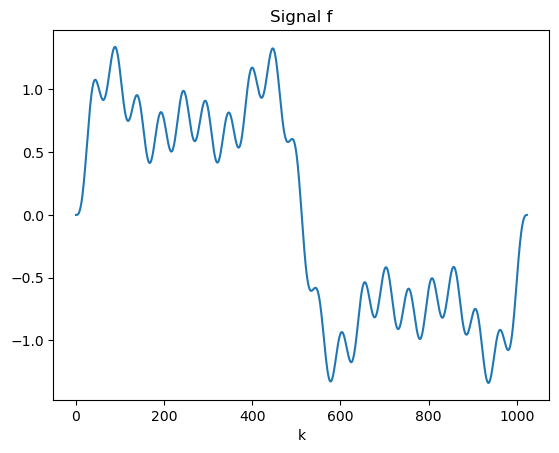

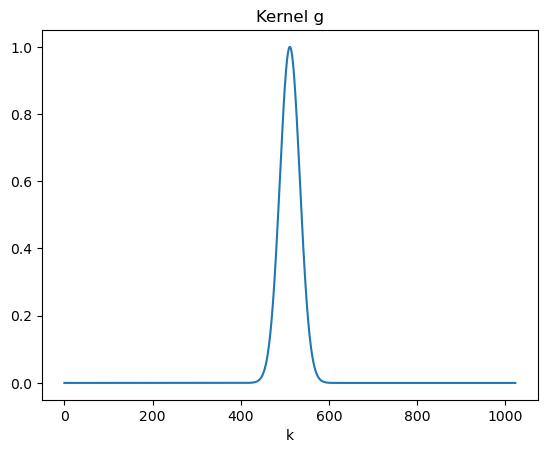

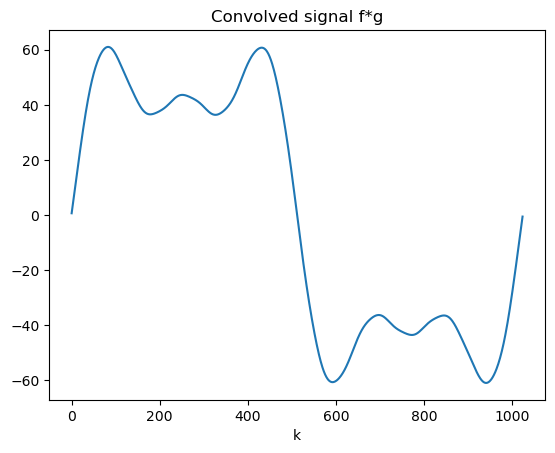

In [3]:
N = 1024
idx = np.arange(N)

f = np.sin( 2 * np.pi * idx / N) + 0.5 *np.sin( 6 * np.pi * idx / N) 
f = f - 0.2 * np.sin( 40 * np.pi * idx / N) + 0.3 * np.sin( 10 * np.pi * idx / N)

plt.plot(idx,f)
plt.title('Signal f')
plt.xlabel('k')
plt.show()

sigma = 1.0
g = np.exp( - (idx - (N-1)/2  )**2 / N * sigma**2 )

plt.plot(idx,g)
plt.title('Kernel g')
plt.xlabel('k')
plt.show()

g = np.roll(g, N//2,0)

# conv = convolve1d(f,g,mode = 'wrap')
conv = convolve(f,g)

plt.plot(idx,np.real(conv))
plt.title('Convolved signal f*g')
plt.xlabel('k')
plt.show() 

(ii) Using Exercise 2.2.6, implement a function *pseudoinv* that computes $f^\dagger = C(g)^\dagger y$ for given $g$ and $y$. Does it successfully reconstruct $f$ when applied to $y = f * g$? 

In [4]:
def pseudoinv(y,g):
    N = g.shape[0]
    g_fft = np.fft.fft(g)
    
    idx_g = np.abs(g_fft) > 0
    inv_g_fft = np.zeros((N), dtype = complex)
    inv_g_fft[idx_g] = 1.0/ g_fft[idx_g]    
    
    f_dagger = np.fft.ifft(inv_g_fft * np.fft.fft(y))
    return f_dagger

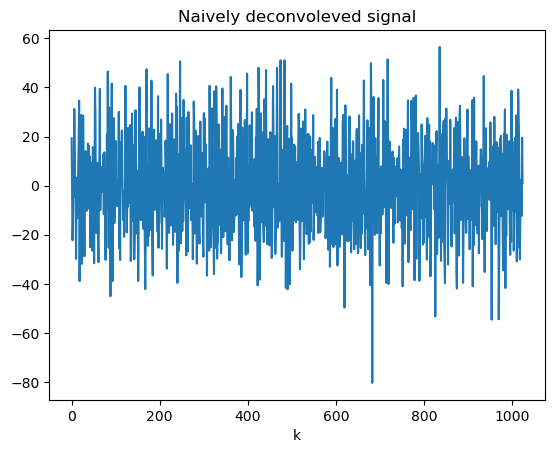

In [5]:
f_dag = pseudoinv(conv, g)

plt.plot(idx,np.real(f_dag))
plt.title('Naively deconvoleved signal')
plt.xlabel('k')
plt.show()

(iii) To understand why *pseudoinv* fails, plot $|F_N g|$ in $\log_{10}$ scale. What do you observe? 

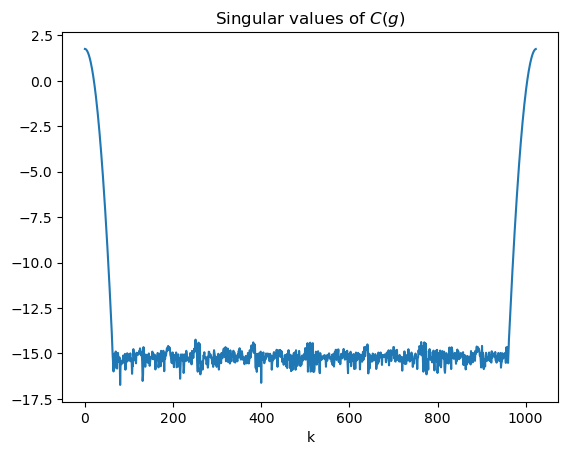

In [6]:
g_fft = np.fft.fft(g)

plt.plot(np.log10(np.abs(g_fft + 1e-16)))
plt.title('Singular values of $C(g)$')
plt.xlabel('k')
plt.show()

We see that the singular values decay exponentially fast, and many are $<10^{-16}$. Computer stores floating numbers up to precision $10^{-9}$ and $10^{-16}$ for single and double precision types. Furthermore, due to the limited number of bits —32 and 64, respectively —converting to binary introduces errors that later affect our computations. Even if the error is of order $10^{-15}$, when we compute the action of the pseudoinverse and products with $\sigma_n^{-1}$, this leads to the reconstruction errors of order $10^1$, as we can see on the plot above.

Implement the truncated SVD and Tikhonov regularization using Exercise 2.2.6. Then, apply them to $y = f * g$ with $\alpha \in \{ 2, 10^{-6}\}$.
Can you recover $f$ now?

In [7]:
def truncatedSVD(y,g, alpha = 1e-6):
    N = g.shape[0]
    g_fft = np.fft.fft(g)
    idx_g = np.abs(g_fft) >= np.sqrt(alpha)
    inv_g_fft = np.zeros((N), dtype = complex)
    inv_g_fft[idx_g] = 1.0/ g_fft[idx_g]    
    f_dagger = np.fft.ifft(inv_g_fft * np.fft.fft(y))
    return f_dagger

def tikhoinov_reg(y,g, alpha = 1e-6):
    N = g.shape[0]
    g_fft = np.fft.fft(g)
    inv_g_fft = g_fft/(alpha + g_fft**2)    
    f_dagger = np.fft.ifft(inv_g_fft * np.fft.fft(y))
    return f_dagger

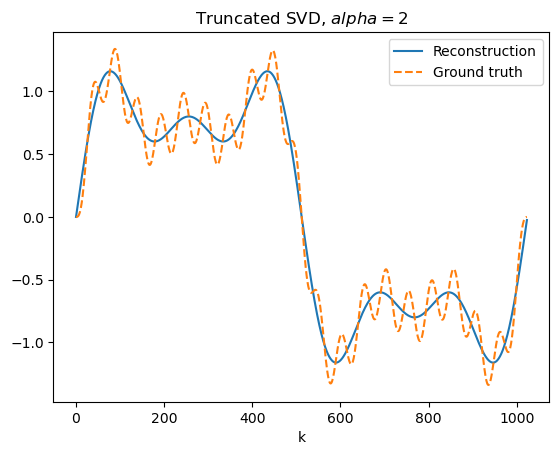

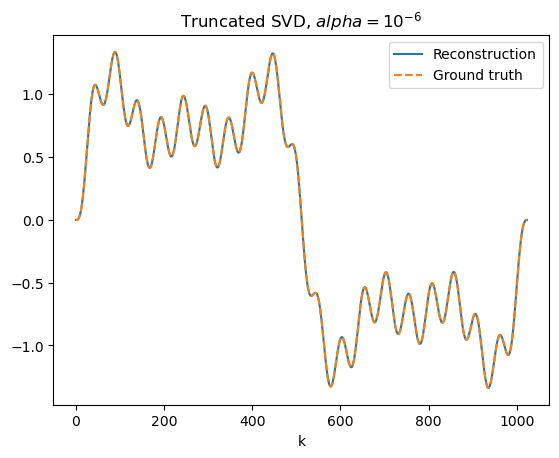

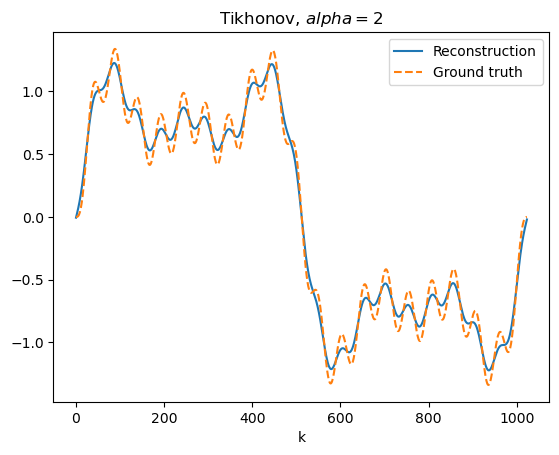

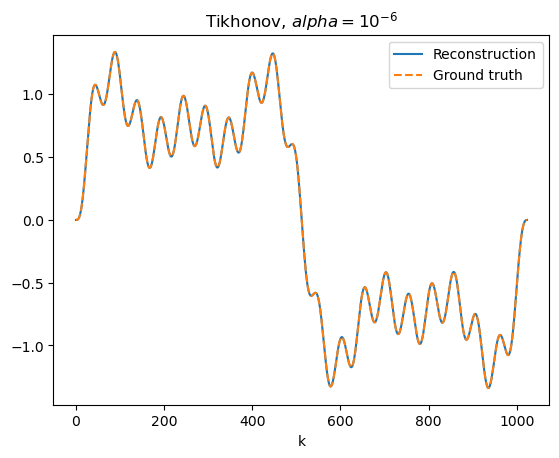

In [8]:
def plot_res(f_est, f, text):
    plt.plot(np.real(f_est))
    plt.plot(f,'--')
    plt.title(text)
    plt.xlabel('k')
    plt.legend(['Reconstruction', 'Ground truth'])
    plt.show()


f_tsvd6 = truncatedSVD(conv, g, 2)
plot_res(f_tsvd6,f,'Truncated SVD, $alpha =2$')

f_tsvd12 = truncatedSVD(conv, g,1e-6)
plot_res(f_tsvd12,f,'Truncated SVD, $alpha = 10^{-6}$')

f_tikh6 = tikhoinov_reg(conv, g,2)
plot_res(f_tikh6,f,'Tikhonov, $alpha = 2$')

f_tikh12 = tikhoinov_reg(conv, g,1e-6)
plot_res(f_tikh12,f,'Tikhonov, $alpha = 10^{-6}$')

(v) Let $e \in \mathbb C^{N}$ with $e_k = \tfrac{0.1}{\sqrt N}\exp(60 \pi i k/N)$, where $i$ is the complex unit $i^2 = -1$.
Plot the output of the implemented regularizations for $y = f * g + e$.

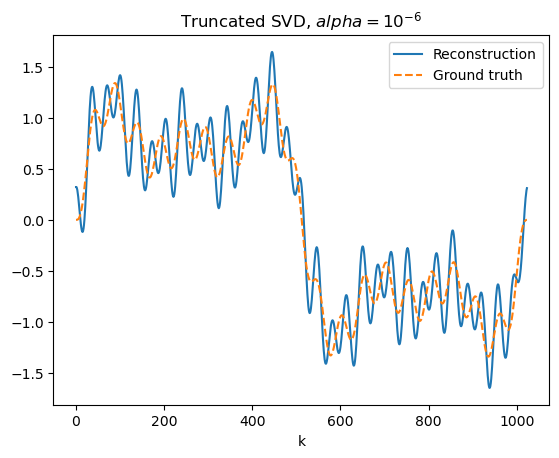

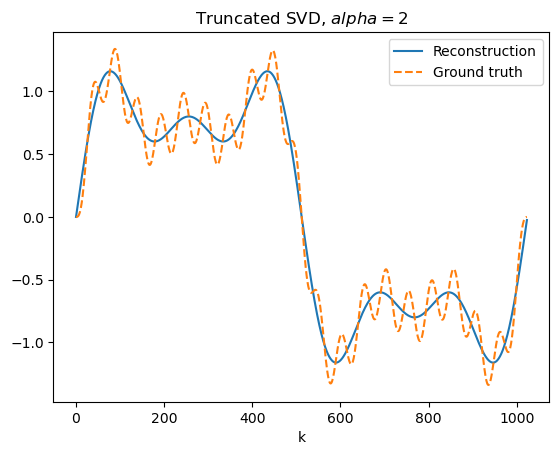

In [9]:
j = 30
delta = 0.1
noise = np.exp(- 2.0j * np.pi * j*idx / N ) / np.sqrt(N)
    
f_tsvd_noisy = truncatedSVD(conv + delta* noise, g)
plot_res(f_tsvd_noisy,f,'Truncated SVD, $alpha =10^{-6}$')

f_tsvd_noisy = truncatedSVD(conv + delta* noise, g,2)
plot_res(f_tsvd_noisy,f,'Truncated SVD, $alpha =2$')

# Bonus: 2D-examples
Convolutions for one-dimensional signals and two-dimensional images work in exactly the same way. Therefore, all of the properties from this problem sheet transfer to 2D. Let's test it on images.

In [10]:
from skimage import data

In [11]:
def convolve2d(f,g):
    f_fft = np.fft.fft2(f)
    g_fft = np.fft.fft2(g)    
    conv = np.fft.ifft2(f_fft * g_fft)
    return conv

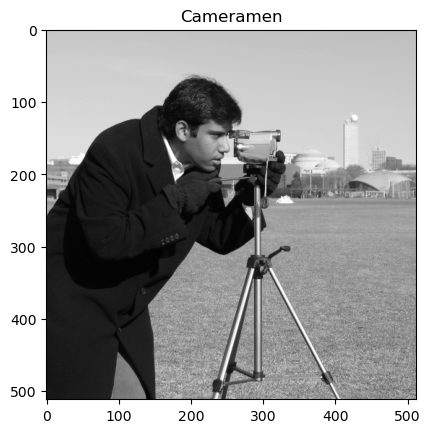

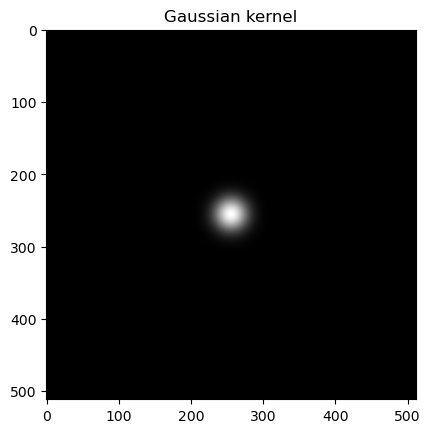

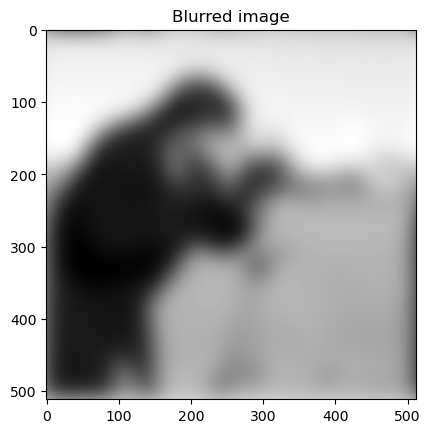

In [12]:
img = data.camera()

N = img.shape[0]

plt.imshow(img, cmap = 'grey')
plt.title('Cameramen')
plt.show()

idx = np.arange(N)
xv, yv = np.meshgrid(idx, idx, indexing='xy')

# Try setting sigma to 0.5, 2 or 3 to reduce the width and the blurring effect of the kernel
sigma = 1.0
gauss = np.exp( - ( (xv - 0.5*(N-1)  )**2 + (yv - 0.5*(N-1)  )**2 ) / N * sigma**2 )

plt.imshow(gauss, cmap = 'grey')
plt.title('Gaussian kernel')
plt.show()

gauss = np.fft.fftshift(gauss)

conv = convolve2d(img, gauss)

plt.imshow(np.real(conv), cmap = 'grey')
plt.title('Blurred image')
plt.show()

In [13]:
def truncated_svd_2d(y,g, alpha = 1e-6):
    g_fft = np.fft.fft2(g)
    idx_g = np.abs(g_fft) >= np.sqrt(alpha)
    inv_g_fft = np.zeros_like(g_fft, dtype = complex)
    inv_g_fft[idx_g] = 1.0/ g_fft[idx_g]
    f_dagger = np.fft.ifft2(inv_g_fft * np.fft.fft2(y))
    return f_dagger

def tikhonov_2d(y,g, alpha = 1e-6):
    g_fft = np.fft.fft2(g)
    inv_g_fft = g_fft/ (alpha + g_fft**2)
    f_dagger = np.fft.ifft2(inv_g_fft * np.fft.fft2(y))
    return f_dagger

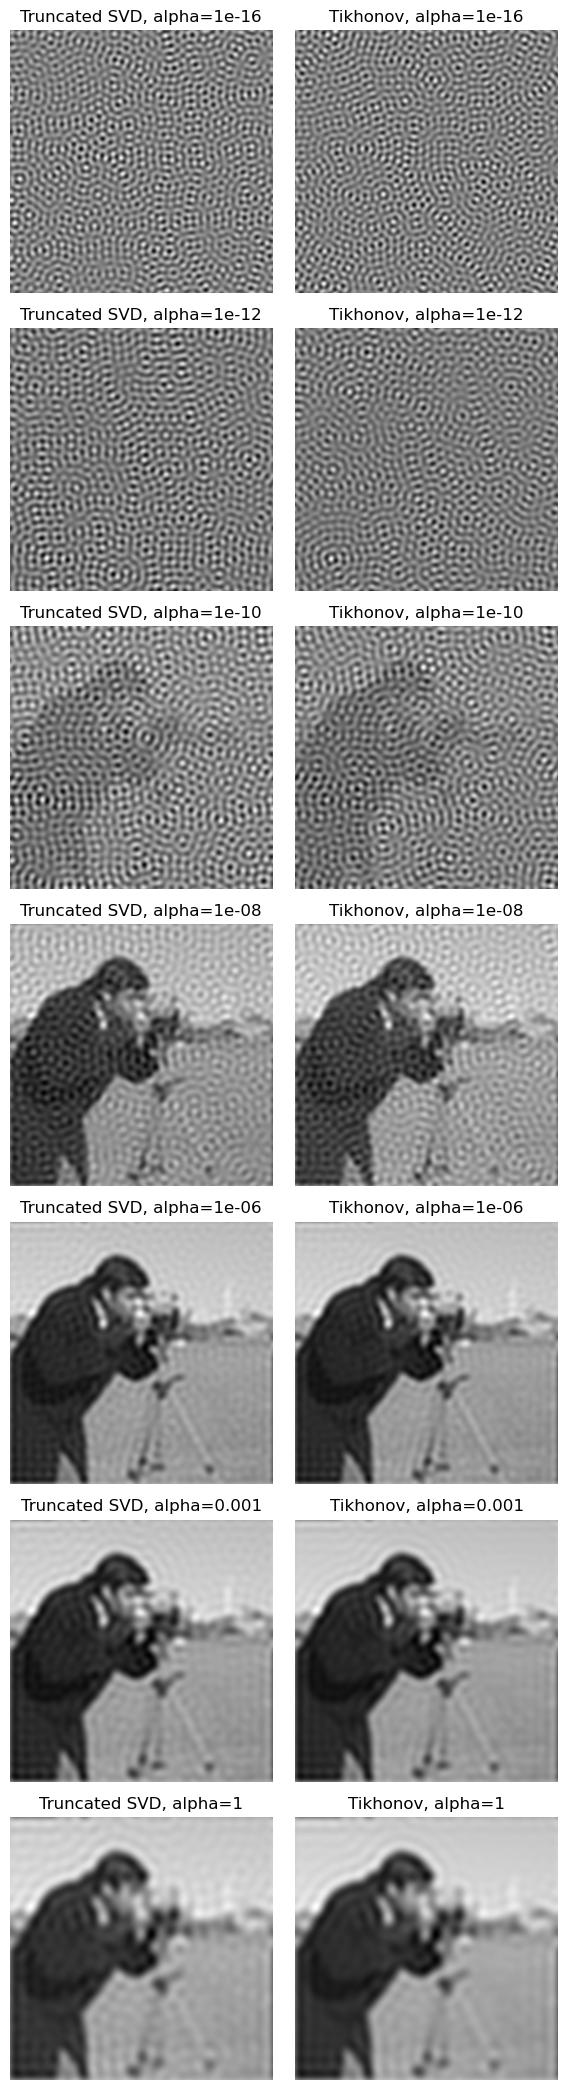

In [25]:
alpha_list = [1e-16, 1e-12, 1e-10, 1e-8, 1e-6, 1e-3,1]

plt.figure(figsize=(3*2, 3*len(alpha_list)))

noise = 0.1*np.random.randn(conv.shape[0],conv.shape[1])

for ai in range(len(alpha_list)):
    alpha = alpha_list[ai]

    img_tsvd = truncated_svd_2d(conv + noise, gauss,alpha)
    plt.subplot(len(alpha_list), 2, ai*2 + 1)
    plt.imshow(np.real(img_tsvd), cmap = 'grey')
    plt.axis('off')
    plt.title(f'Truncated SVD, alpha={alpha}')
          
    img_tikh = tikhonov_2d(conv + noise, gauss,alpha)

    plt.subplot(len(alpha_list), 2, ai*2 + 2)
    plt.imshow(np.real(img_tikh), cmap = 'grey')
    plt.axis('off')
    plt.title(f'Tikhonov, alpha={alpha}')
    
plt.tight_layout()
plt.show()